In [2]:
!pip install -q timm==1.0.9 albumentations==1.4.18 opencv-python-headless scikit-learn pandas matplotlib seaborn

import os
import cv2
import yaml
import torch
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import albumentations as A
from albumentations.pytorch import ToTensorV2
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import GroupKFold

# Configuración global del pipeline
CONFIG = {
    "seed": 42,
    "n_splits": 5,
    "image_size": 384,
    "batch_size": 32,
    "clahe_clip_limit": 2.0,
    "clahe_tile_grid": (8, 8),
    "imagenet_mean": [0.485, 0.456, 0.406],
    "imagenet_std": [0.229, 0.224, 0.225],
    "target_columns": [
        "No Finding", "Enlarged Cardiomediastinum", "Cardiomegaly",
        "Lung Opacity", "Lung Lesion", "Edema", "Consolidation",
        "Pneumonia", "Atelectasis", "Pneumothorax", "Pleural Effusion",
        "Pleural Other", "Fracture", "Support Devices"
    ],
    "u_smoothing_cols": ["Atelectasis", "Consolidation", "Edema"],
    "u_smoothing_value": 0.55
}

np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])
print("Entorno configurado correctamente. PyTorch:", torch.__version__, "| GPU disponible:", torch.cuda.is_available())

/usr/local/lib/python3.13/dist-packages/albumentations/__init__.py:13: UserWarning: A new version of Albumentations is available: 2.0.8 (you have 1.4.18). Upgrade using: pip install -U albumentations. To disable automatic update checks, set the environment variable NO_ALBUMENTATIONS_UPDATE to 1.
  check_for_updates()


Entorno configurado correctamente. PyTorch: 2.14.1+cpu | GPU disponible: False


In [3]:
from google.colab import files

if not os.path.exists("/root/.kaggle/kaggle.json"):
    print("Selecciona y sube tu archivo kaggle.json:")
    files.upload()
    !mkdir -p ~/.kaggle
    !cp kaggle.json ~/.kaggle/
    !chmod 600 ~/.kaggle/kaggle.json

!mkdir -p data_chexpert
!kaggle datasets download -d ashery/chexpert -p data_chexpert --unzip
!ls -lh data_chexpert

Selecciona y sube tu archivo kaggle.json:


Saving Pipeline_Preprocesamiento_CheXpert_DL.ipynb to Pipeline_Preprocesamiento_CheXpert_DL.ipynb
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/ashery/chexpert
License(s): CC0-1.0
100% 10.7G/10.7G [01:55<00:00, 99.7MB/s]

total 26M
drwxr-xr-x 64542 root root 2.0M Nov 17 19:47 train
-rw-r--r--     1 root root  24M Nov 17 19:44 train.csv
drwxr-xr-x   202 root root 4.0K Nov 17 19:47 valid
-rw-r--r--     1 root root  33K Nov 17 19:47 valid.csv


Total registros originales en CheXpert train.csv: 223,414
Distribución Frontal vs Lateral:
Frontal/Lateral
Frontal    191027
Lateral     32387
Name: count, dtype: int64

Total radiografías frontales válidas: 191,027
Total pacientes únicos reales: 64,534


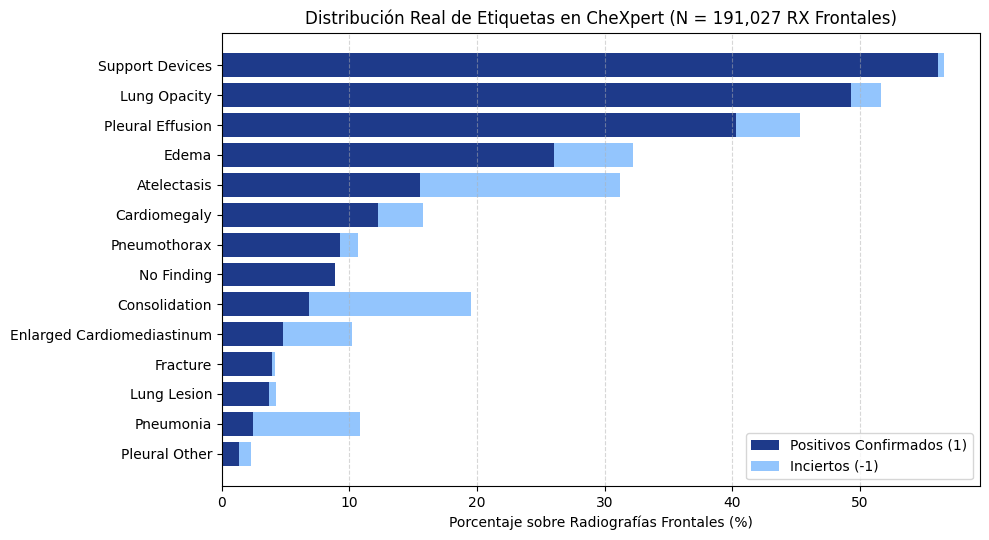

In [4]:
# Detectar ruta del CSV descargado
train_csv_path = "data_chexpert/train.csv"
raw_df = pd.read_csv(train_csv_path)

print(f"Total registros originales en CheXpert train.csv: {len(raw_df):,}")
print(f"Distribución Frontal vs Lateral:\n{raw_df['Frontal/Lateral'].value_counts()}\n")

# 1. Filtrar exclusivamente radiografías frontales (PA / AP)
df = raw_df[raw_df["Frontal/Lateral"] == "Frontal"].copy().reset_index(drop=True)

# 2. Extraer patient_id real desde la ruta del archivo
df["patient_id"] = df["Path"].apply(lambda p: p.split("/")[2])
df["full_path"] = df["Path"].apply(
    lambda p: os.path.join("data_chexpert", p.replace("CheXpert-v1.0-small/", ""))
)

print(f"Total radiografías frontales válidas: {len(df):,}")
print(f"Total pacientes únicos reales: {df['patient_id'].nunique():,}")

# 3. Gráfica real de prevalencia de etiquetas Positivas (1) e Inciertas (-1)
target_cols = CONFIG["target_columns"]
pos_pct = [(df[c] == 1.0).mean() * 100 for c in target_cols]
unc_pct = [(df[c] == -1.0).mean() * 100 for c in target_cols]

eda_df = pd.DataFrame({
    "Patología": target_cols,
    "Positivos (%)": pos_pct,
    "Inciertos U-label (%)": unc_pct
}).sort_values("Positivos (%)", ascending=True)

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(eda_df["Patología"], eda_df["Positivos (%)"], color="#1E3A8A", label="Positivos Confirmados (1)")
ax.barh(eda_df["Patología"], eda_df["Inciertos U-label (%)"], left=eda_df["Positivos (%)"], color="#93C5FD", label="Inciertos (-1)")
ax.set_xlabel("Porcentaje sobre Radiografías Frontales (%)")
ax.set_title(f"Distribución Real de Etiquetas en CheXpert (N = {len(df):,} RX Frontales)")
ax.legend(loc="lower right")
ax.grid(axis="x", linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

In [5]:
# 1. Tratamiento de NaN y U-Smoothing (-1 -> 0.55 en clases ambiguas, 0.0 en el resto)
for col in CONFIG["target_columns"]:
    df[col] = df[col].fillna(0.0)
    if col in CONFIG["u_smoothing_cols"]:
        df[col] = df[col].replace(-1.0, CONFIG["u_smoothing_value"])
    else:
        df[col] = df[col].replace(-1.0, 0.0)

# 2. Partición GroupKFold estricta por patient_id
gkf = GroupKFold(n_splits=CONFIG["n_splits"])
df["fold"] = -1
for fold, (_, val_idx) in enumerate(gkf.split(df, groups=df["patient_id"])):
    df.loc[val_idx, "fold"] = fold

# 3. Verificación de cero fuga de datos (Data Leakage Check)
print("Auditoría de partición GroupKFold (5 Folds):")
for f in range(CONFIG["n_splits"]):
    train_df = df[df["fold"] != f]
    val_df = df[df["fold"] == f]
    overlap = len(set(train_df["patient_id"]).intersection(set(val_df["patient_id"])))
    assert overlap == 0, f"Fuga detectada en fold {f}"
    print(f"  Fold {f}: Train = {len(train_df):,} RX ({train_df['patient_id'].nunique():,} pac.) | "
          f"Val = {len(val_df):,} RX ({val_df['patient_id'].nunique():,} pac.) | Solapamiento = {overlap}")

Auditoría de partición GroupKFold (5 Folds):
  Fold 0: Train = 152,821 RX (51,627 pac.) | Val = 38,206 RX (12,907 pac.) | Solapamiento = 0
  Fold 1: Train = 152,821 RX (51,627 pac.) | Val = 38,206 RX (12,907 pac.) | Solapamiento = 0
  Fold 2: Train = 152,822 RX (51,628 pac.) | Val = 38,205 RX (12,906 pac.) | Solapamiento = 0
  Fold 3: Train = 152,822 RX (51,627 pac.) | Val = 38,205 RX (12,907 pac.) | Solapamiento = 0
  Fold 4: Train = 152,822 RX (51,627 pac.) | Val = 38,205 RX (12,907 pac.) | Solapamiento = 0


In [6]:
def apply_clahe_and_pad(image_bgr: np.ndarray, target_size: int = 384, clip_limit: float = 2.0, tile_grid=(8, 8)) -> np.ndarray:
    """Aplica CLAHE en luminancia y redimensiona preservando relación de aspecto con zero-padding."""
    gray = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2GRAY)
    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid)
    enhanced = clahe.apply(gray)

    h, w = enhanced.shape
    scale = target_size / max(h, w)
    new_w, new_h = int(round(w * scale)), int(round(h * scale))
    resized = cv2.resize(enhanced, (new_w, new_h), interpolation=cv2.INTER_CUBIC)

    canvas = np.zeros((target_size, target_size), dtype=np.uint8)
    y_offset = (target_size - new_h) // 2
    x_offset = (target_size - new_w) // 2
    canvas[y_offset:y_offset + new_h, x_offset:x_offset + new_w] = resized

    return cv2.cvtColor(canvas, cv2.COLOR_GRAY2RGB)

def get_transforms(is_train: bool = True):
    """Data Augmentation clínicamente válido (sin HorizontalFlip para conservar lateralidad cardíaca)."""
    if is_train:
        return A.Compose([
            A.Affine(scale=(0.95, 1.05), translate_percent=(-0.05, 0.05), rotate=(-7, 7), p=0.7),
            A.RandomBrightnessContrast(brightness_limit=0.10, contrast_limit=0.10, p=0.5),
            A.Normalize(mean=CONFIG["imagenet_mean"], std=CONFIG["imagenet_std"]),
            ToTensorV2(),
        ])
    return A.Compose([
        A.Normalize(mean=CONFIG["imagenet_mean"], std=CONFIG["imagenet_std"]),
        ToTensorV2(),
    ])

class CheXpertDataset(Dataset):
    def __init__(self, dataframe, target_cols, image_size=384, is_train=True):
        self.df = dataframe.reset_index(drop=True)
        self.paths = self.df["full_path"].values
        self.labels = self.df[target_cols].values.astype("float32")
        self.image_size = image_size
        self.transforms = get_transforms(is_train=is_train)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        img = cv2.imread(self.paths[idx])
        if img is None:
            raise FileNotFoundError(f"Imagen no encontrada: {self.paths[idx]}")
        img_proc = apply_clahe_and_pad(
            img,
            target_size=self.image_size,
            clip_limit=CONFIG["clahe_clip_limit"],
            tile_grid=CONFIG["clahe_tile_grid"]
        )
        tensor_img = self.transforms(image=img_proc)["image"]
        target = torch.tensor(self.labels[idx], dtype=torch.float32)
        return tensor_img, target

print("Pipeline de preprocesamiento y clase CheXpertDataset definidos correctamente.")

Pipeline de preprocesamiento y clase CheXpertDataset definidos correctamente.


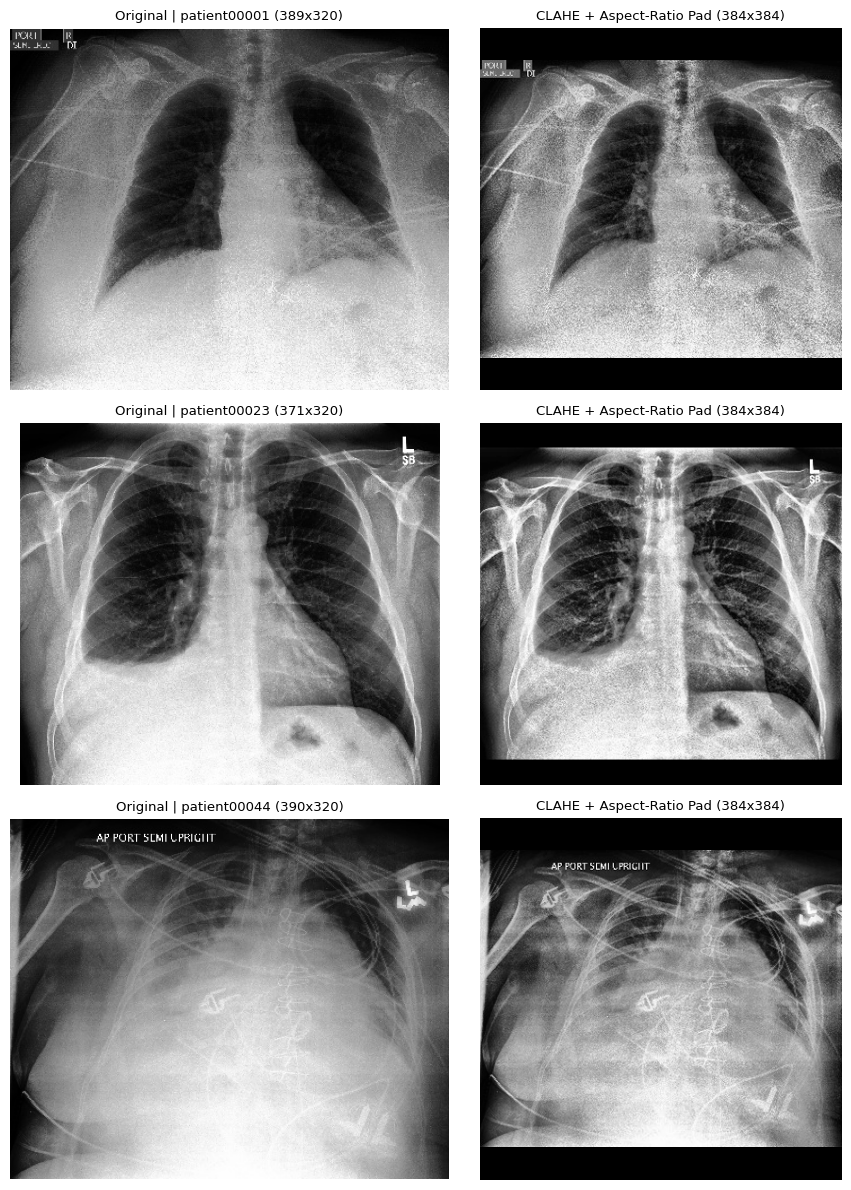

Batch de imágenes verificado -> Shape: (32, 3, 384, 384) | Dtype: torch.float32
Rango normalizado -> Min: -2.118, Max: 2.640, NaNs: 0
Batch de etiquetas (14 patologías) -> Shape: (32, 14) | Dtype: torch.float32


In [7]:
# 1. Visualización comparativa real en 3 radiografías del dataset
fig, axes = plt.subplots(3, 2, figsize=(9, 12))

for idx in range(3):
    row = df.iloc[idx * 50]
    raw_bgr = cv2.imread(row["full_path"])
    proc_rgb = apply_clahe_and_pad(raw_bgr, target_size=CONFIG["image_size"])

    axes[idx, 0].imshow(cv2.cvtColor(raw_bgr, cv2.COLOR_BGR2RGB))
    axes[idx, 0].set_title(f"Original | {row['patient_id']} ({raw_bgr.shape[1]}x{raw_bgr.shape[0]})", fontsize=9.5)
    axes[idx, 0].axis("off")

    axes[idx, 1].imshow(proc_rgb)
    axes[idx, 1].set_title(f"CLAHE + Aspect-Ratio Pad (384x384)", fontsize=9.5)
    axes[idx, 1].axis("off")

plt.tight_layout()
plt.show()

# 2. Prueba real del DataLoader (Fold 0)
train_ds = CheXpertDataset(df[df["fold"] != 0].head(64), CONFIG["target_columns"], image_size=384, is_train=True)
train_loader = DataLoader(train_ds, batch_size=CONFIG["batch_size"], shuffle=True, num_workers=2)

batch_x, batch_y = next(iter(train_loader))
print(f"Batch de imágenes verificado -> Shape: {tuple(batch_x.shape)} | Dtype: {batch_x.dtype}")
print(f"Rango normalizado -> Min: {batch_x.min():.3f}, Max: {batch_x.max():.3f}, NaNs: {torch.isnan(batch_x).sum().item()}")
print(f"Batch de etiquetas (14 patologías) -> Shape: {tuple(batch_y.shape)} | Dtype: {batch_y.dtype}")